# Content

Tests the analysis pipeline

# Imports

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
import os
import sklearn

from helpers import *
from helpers_analysis import * 
from implementations import * 

# Useful functions

In [62]:
def logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, initial_w, max_iters, gamma):
    """Implementation of logistic regression.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        initial_w:  shape=(D, 1)
        max_iters: scalar denoting the total number of iterations
        gamma: scalar denoting the stepsize


    Returns:
        w: numpy array of shape=(D, ) denoting the final model parameters
        loss: scalar denoting final loss value
    """

    w = initial_w
    N = len(y_tr)
    losses_train = []
    losses_test = []
    for n_iter in range(max_iters):

        #Index random choice and update
        idx = np.random.randint(N)
        grad = tx_tr[idx].T*(1/(1+np.exp(-tx_tr[idx]*w)) - y_tr[idx])/N
        w = w - gamma * grad

        #Loss computations
        loss_train = np.mean(-y_tr*(tx_tr@w) + np.log(1 + np.exp(tx_tr@w)))
        losses_train.append(loss_train)
        loss_test = np.mean(-y_te*(tx_te@w) + np.log(1 + np.exp(tx_te@w)))
        losses_test.append(loss_test)
    
    return w, losses_train, losses_test

def reg_logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, lambda_, initial_w, max_iters, gamma):
    """Implementation of logistic regression.

    Args:
        y:  shape=(N, 1)
        tx: shape=(N, D)
        initial_w:  shape=(D, 1)
        max_iters: scalar denoting the total number of iterations
        gamma: scalar denoting the stepsize


    Returns:
        w: numpy array of shape=(D, ) denoting the final model parameters
        loss: scalar denoting final loss value
    """

    w = initial_w
    N = len(y_tr)
    losses_train = []
    losses_test = []
    for n_iter in range(max_iters):
        idx = np.random.randint(N)
        grad = tx_tr[idx].T*(1/(1+np.exp(-tx_tr[idx]*w)) - y_tr[idx])/N + 2 * lambda_ * w 
        w = w - gamma * grad

        #Loss computations
        loss_train = np.mean(-y_tr*(tx_tr@w) + np.log(1 + np.exp(tx_tr@w)))
        losses_train.append(loss_train)
        loss_test = np.mean(-y_te*(tx_te@w) + np.log(1 + np.exp(tx_te@w)))
        losses_test.append(loss_test)

    loss = np.mean(-y_tr*(tx_tr@w) + np.log(1 + np.exp(tx_tr@w)))
    
    return w, losses_train, losses_test

In [136]:
def display_losses(losses_train, losses_test, title) :
    #Loss display: pure logistic
    plt.plot(losses_train, label="Train")
    plt.plot(losses_test, label="Test")
    plt.ylabel("Loss value")
    plt.xlabel("Iteration")
    plt.title(f"Loss value during optimization, {title}")
    plt.legend(loc="upper right")
    plt.savefig(f"image/losses_{title}.png", dpi=300)
    plt.show()

In [134]:
def confusion_matrix_custom(y_te, y_te_pred) :
    """Computes the confusion matrix (cm_custom) between true labels (y_te) and predicted labels (y_te_pred)"""
    cm_custom = np.zeros((2,2))

    for i,elt in enumerate(y_te_pred) :
        #Class 0 which is true (True negative)
        if elt == 0 and elt == y_te[i] :
            cm_custom[1,1] += 1

        #Class 0 which is false (under-estimated ==> death) (false negative)
        elif elt == 0 and elt != y_te[i] :
            cm_custom[0, 1] += 1

        #Class 1 which is false (over-prediction) (false positive)
        elif elt == 1 and elt != y_te[i] :
            cm_custom[1, 0] += 1
            
        #Class 1 which is true (True negative)
        elif elt == 1 and elt == y_te[i] :
            cm_custom[0, 0] += 1

    cm_ratio_custom = cm_custom/len(y_te)

    return(cm_custom, cm_ratio_custom)

def display_confusion_matrix(cm, cm_ratio, title) :
    """Display confusion matrix only with matplotlib. Convention: positive when class 1 (ie heart disease)"""
    
    L_labels = [["True Positive", "False Negative"], ["False Positive", "False positive"]]

    #Figure creation
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    #Heatmap
    im = ax[0].imshow(cm, cmap='Blues', origin='upper')
    fig.colorbar(im, ax=ax[0])

    #Plot values and type
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax[0].text(
                j, i, f'{cm[i, j]:.0f} \n {L_labels[i][j]}',
                ha='center',
                va='center',
                color='black'
            )

    ax[0].set_title(f"confusion_matrix_{title}")

    #Heatmap ratio
    im = ax[1].imshow(cm, cmap='Blues', origin='upper')
    fig.colorbar(im, ax=ax[1])

    #Plot values and type
    for i in range(cm.shape[1]):
        for j in range(cm.shape[1]):
            ax[1].text(
                j, i, f'{cm[i, j]:.0f} \n {L_labels[i][j]}',
                ha='center',
                va='center',
                color='black'
            )

    ax[1].set_title(f"confusion_matrix_ratio_{title}")

    fig.savefig(f"image/confusion_matrix_{title}.png", dpi=300)
    plt.show()

# 1-Training

#### a-Parameters

In [138]:
#Data directory
DATA_DIR = ""

#Preprocessing
imputation = False

#Pipeline choice
launch_pure_log = False
launch_reg_log = False
launch_pure_log_sgd = True
launch_reg_log_sgd = True
launch_kNN = False

#### b-Training phase

Reduced to 3 features.
['_HCVU651', '_AGE80', '_AGE_G']
Load and preprocess train: OK 

Load and preprocess test: OK 

Pure logistic regression SGD: OK 



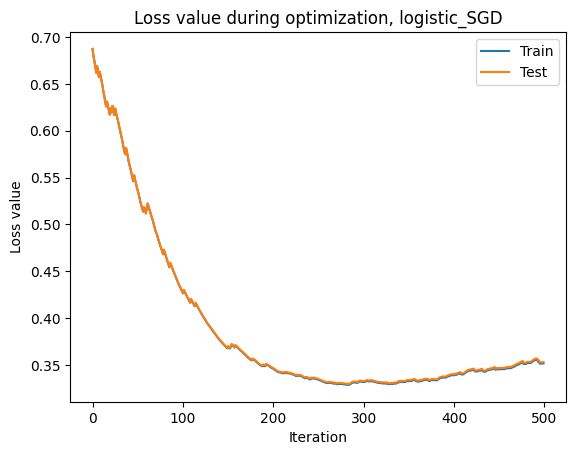

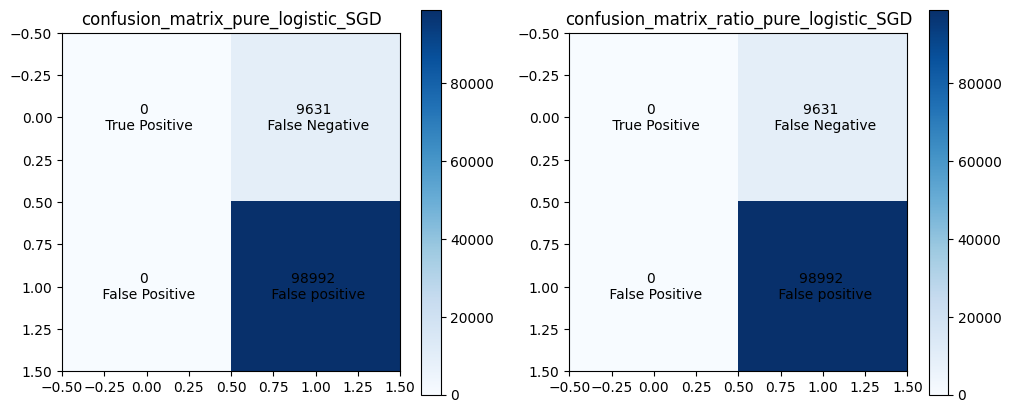

Penalized logistic regression SGD: OK 



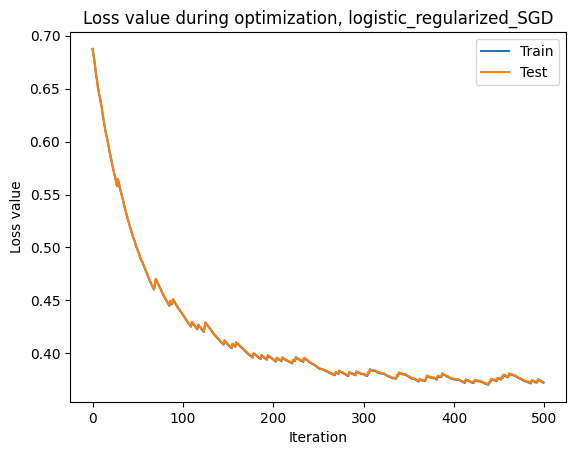

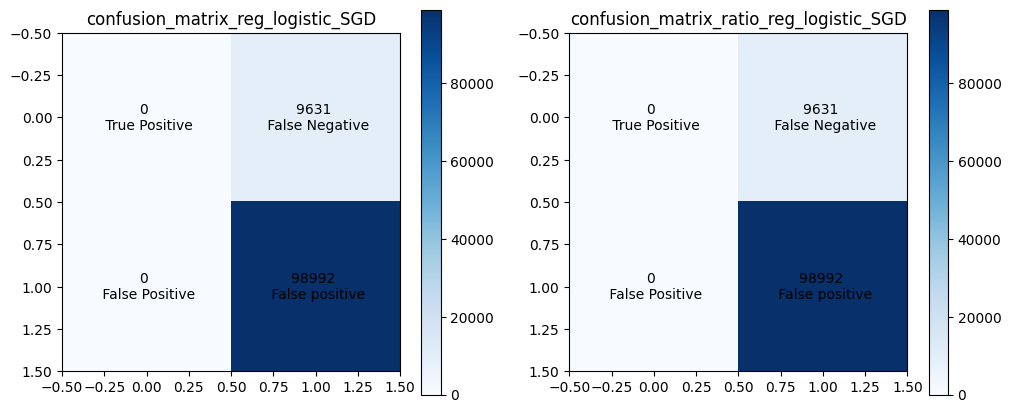

In [139]:
#### LOAD AND PREPROCESS ####

#Train
x_train, y_train, cont_params, cat_params, mask = load_data_train(DATA_DIR, imputation=imputation)
print("Load and preprocess train: OK \n")

#Test
x_test = load_data_test(DATA_DIR, cont_params, cat_params, mask, imputation=imputation)
print("Load and preprocess test: OK \n")



#### PREPROCESS FOR CLASSIFIERS ####

#Dtype (to change in case of being unable to allocate matrices with large type. Can be changed to np.float32)
dtype_array = np.float32

#Train/validation split
#Mask definition
rng = np.random.default_rng()
n = len(y_train)
ratio_mask = 33
mask = rng.random(n) >= ratio_mask / 100

#Train/validation split
x_tr = x_train[mask]
y_tr = y_train[mask]
x_te = x_train[~mask]
y_te = y_train[~mask]

#Add intercept
tx_tr = np.c_[np.ones((x_tr.shape[0], 1)), x_tr]
tx_tr = tx_tr.astype(dtype_array)
tx_te = np.c_[np.ones((x_te.shape[0], 1)), x_te]
tx_te = tx_te.astype(dtype_array)

# Initialize weights
initial_w = np.zeros(tx_tr.shape[1])



#### LOGISTIC REGRESSION ####
#Optimization params
max_iters = 500
gamma = 0.01
lambda_ = 0.5

#Pure logistic regression
if launch_pure_log == True :
    w_log, loss_log = logistic_regression(y_tr, tx_tr, initial_w, max_iters, gamma)
    print("Pure logistic regression: OK \n")

    #Class choice
    logistic_mask_log = sigmoid(tx_te @ w_log) >= 0.5
    y_te_pred_log = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log[logistic_mask_log] = 1

    #Confusion matrix display
    confusion_matrix_log, confusion_matrix_ratio_log = confusion_matrix_custom(y_te, y_te_pred_log)
    display_confusion_matrix(confusion_matrix_log, confusion_matrix_ratio_log, "pure_logistic")


#Penalized logistic regression
if launch_reg_log == True :
    w_log_reg, loss_log_reg = reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)
    print("Penalized logistic regression: OK \n")

    #Class choice
    logistic_mask_log_reg = sigmoid(tx_te @ w_log_reg) >= 0.5
    y_te_pred_log_reg = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log_reg[logistic_mask_log_reg] = 1

    #Confusion matrix display
    confusion_matrix_log_reg, confusion_matrix_ratio_log_reg = confusion_matrix_custom(y_te, y_te_pred_log_reg)
    display_confusion_matrix(confusion_matrix_log_reg, confusion_matrix_ratio_log, "reg_logistic")



#### LOGISTIC REGRESSION SGD ####

#Pure logistic regression sgd
if launch_pure_log_sgd == True :
    #Optimization params
    max_iters = 500
    gamma = 5000
    w_log_sgd, losses_train_log_sgd, losses_test_log_sgd = logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, initial_w, max_iters, gamma)
    print("Pure logistic regression SGD: OK \n")

    #Losses display
    display_losses(losses_train_log_sgd, losses_test_log_sgd, "logistic_SGD")

    #Class choice
    logistic_mask_log_sgd = sigmoid(tx_te @ w_log_sgd) >= 0.5
    y_te_pred_log_sgd = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log_sgd[logistic_mask_log_sgd] = 1

    #Display
    confusion_matrix_log_sgd, confusion_matrix_ratio_log_sgd = confusion_matrix_custom(y_te, y_te_pred_log_sgd)
    display_confusion_matrix(confusion_matrix_log_sgd, confusion_matrix_ratio_log, "pure_logistic_SGD")

#Penalized logistic regression sgd
if launch_reg_log_sgd == True :
    #Optimization params
    max_iters = 500
    gamma = 5000
    lambda_ = 0.0000005
    w_log_reg_sgd, losses_train_log_reg_sgd, losses_test_log_reg_sgd = reg_logistic_regression_sgd(y_tr, tx_tr, y_te, tx_te, lambda_, initial_w, max_iters, gamma)
    print("Penalized logistic regression SGD: OK \n")

    #Losses display
    display_losses(losses_train_log_reg_sgd, losses_test_log_reg_sgd, "logistic_regularized_SGD")

    #Class choice
    logistic_mask_log_reg_sgd = sigmoid(tx_te @ w_log_reg_sgd) >= 0.5
    y_te_pred_log_reg_sgd = np.zeros((np.shape(tx_te)[0],1))
    y_te_pred_log_reg_sgd[logistic_mask_log_reg_sgd] = 1

    #Confusion matrix display
    confusion_matrix_log_reg_sgd, confusion_matrix_ratio_log_reg_sgd = confusion_matrix_custom(y_te, y_te_pred_log_reg_sgd)
    display_confusion_matrix(confusion_matrix_log_reg_sgd, confusion_matrix_ratio_log, "reg_logistic_SGD")


#### kNN ####
if launch_kNN == True :
    #Fit
    neigh = sklearn.neighbors.KNeighborsClassifier(n_neighbors=1)
    neigh.fit(x_tr, y_tr.ravel())

    #Predict
    y_te_pred_kNN = neigh.predict(x_te)
    print("kNN: OK \n")

    #Confusion matrix display
    confusion_matrix_kNN, confusion_matrix_ratio_kNN = confusion_matrix_custom(y_te, y_te_pred_kNN)
    display_confusion_matrix(confusion_matrix_kNN, confusion_matrix_ratio_log, "kNN")